# Scaling study: SBC, SBC + AA, QETU and QETU + AA vs N at controlled gap and overlap

**Model.** Open dimerised $J_1$-$J_2$ chain $H = J_1\sum_i (1+(-1)^i\delta)\,\mathbf S_i\cdot\mathbf S_{i+1} + J_2\sum_i \mathbf S_i\cdot\mathbf S_{i+2}$, $J_2 = 0.2411$.

**Controlled knobs.**
* **Gap:** at every $N$ the dimerisation $\delta$ is solved so that the relative gap $\eta = \Delta/W$ (the gap the filter resolves, $W = E_{\max}-E_0$) hits each target. Holding $\eta$ fixed isolates the explicit $N$ dependence.
* **Overlap:** trial $= e^{-i\epsilon\sum_i(-1)^iZ_i}|E_0\rangle$ (exact ground state + staggered Rz), $\epsilon$ solved so $|\langle E_0|\text{trial}\rangle|^2 = \gamma$. Exact preparation is not costed: every number is **filter cost only**.

**Methods** (same filter polynomial $F=\prod_{k<K}\cos(2^k\tau H_s)^r$, $H_s=(H-E_0)/W$, $\tau=\pi/(1+\eta)$, second-order Strang steps):

| method | qubits | success |
|---|---|---|
| SBC (RUS) | $N+1$ | ancilla measured and reset after each pulse, $1/p$ attempts |
| SBC + AA | $N+Kr$ | one ancilla per pulse, $k\approx\pi/4\sqrt p$ Grover rounds |
| QETU (RUS) | $N+1$ | $d=r(2^K-1)$ controlled steps interleaved with $d+1$ ancilla $R_x(\phi_j)$ |
| QETU + AA | $N+1$ | QETU inside AA, $R_{good}$ = single-qubit $Z$ |

**Simulation.** Exact in the $S^z=0$ sector: the Strang step is diagonalised once per $(N,\eta,n)$, so $p$ and $1-F$ of the Trotterised circuit are exact for every $(K,r)$ and every $\gamma$. QETU on the same Strang step applies the same polynomial to the same eigenphases, so its $p$ and $1-F$ equal SBC's (checked gate by gate in `filter_walkthrough.ipynb`); the gate counts differ.

**Costs.** CNOT and non-Clifford $R_z$ (angle not a multiple of $\pi/2$) after compiling to {CX, Rz, SX, X}. Per method and point, $(K,r,n)$ minimises CNOT per success with $1-F\le\epsilon$ at $n$ **and** at the next finer $n$. AA assumes $p$ is known; it is used only where it has $k\ge1$ rounds.

In [1]:
# ---- parameters
NS       = [6, 8, 10, 12, 14, 16]          # N = 16: ~100 s per Strang spectrum (12870-dim sector)
ETAS     = [0.015, 0.03, 0.06, 0.1]         # relative gap η = Δ/W targets (reachable for N = 6..16)
GAMMAS   = [0.05, 0.1, 0.25, 0.5, 0.9]      # trial overlaps
J1, J2   = 1.0, 0.2411
EPS      = 1e-2
N_GRID   = [1, 2, 3, 4, 6, 8, 12, 16]
K_MAX, R_MAX = 16, 12
DELTA_RANGE = (-0.32, 0.6)                  # monotonic part of η(δ)

import os, sys, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display
sys.path.insert(0, os.path.abspath("."))                       # run from ORNL/
from ornl import Chain
from ornl.trotter import step_spectrum
from qiskit import QuantumCircuit, transpile
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
METHODS = ["SBC", "SBC+AA", "QETU", "QETU+AA"]

## 1. Gate-count model, checked against real Qiskit circuits

Controlled bond $e^{-i\phi(XX+YY+ZZ)Z_a}$ = Clifford Bell change + 4-CNOT parity network: **6 CNOT, 3 non-Clifford Rz**. A controlled run of $m$ merged Strang steps has $(2B-2)m+1$ blocks ($B=2N-3$ bonds) plus one ancilla Rz for $-E_0/W$. SBC merges steps inside each pulse; QETU cannot merge across its $R_x(\phi_j)$. Multi-controlled Z (AA reflections) is counted from Qiskit's synthesis. The model is a slight upper bound (Qiskit cancels ~6% of the CNOTs between neighbouring blocks).

In [2]:
CLIFF = lambda x: abs(x / (np.pi / 2) - round(x / (np.pi / 2))) < 1e-9

def counts(qc):
    t = transpile(qc, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1)
    rz = [float(g.operation.params[0]) for g in t.data if g.operation.name == "rz"]
    return np.array([t.count_ops().get("cx", 0), sum(not CLIFF(x) for x in rz)])

def blocks(N, m):
    return (2 * (2 * N - 3) - 2) * m + 1

def sbc_attempt(N, K, r, n):
    b = sum(blocks(N, n * 2 ** k) for k in range(K)) * r
    return np.array([6 * b, 3 * b + K * r])

def qetu_attempt(N, K, r, n):
    d = r * (2 ** K - 1)
    return np.array([6 * d * blocks(N, n), d * (3 * blocks(N, n) + 1) + d + 1])

_mcz = {}
def mcz(nq):
    if nq not in _mcz:
        qc = QuantumCircuit(nq); qc.x(range(nq))
        if nq == 1: qc.z(0)
        else: qc.h(nq - 1); qc.mcx(list(range(nq - 1)), nq - 1); qc.h(nq - 1)
        qc.x(range(nq)); _mcz[nq] = counts(qc)
    return _mcz[nq]

def bond_block(qc, i, j, a, phi):
    qc.cx(i, j); qc.h(i)
    qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a); qc.rz(-2 * phi, a); qc.cx(i, a); qc.rz(2 * phi, a); qc.cx(j, a)
    qc.h(i); qc.cx(i, j)
def ctrl_run(qc, ch, a, t, steps):
    one = list(range(len(ch.bonds))) + list(range(len(ch.bonds)))[::-1]; seq = []
    for b in one * steps:
        if seq and seq[-1][0] == b: seq[-1][1] += 1
        else: seq.append([b, 1])
    for b, w in seq:
        i, j, J = ch.bonds[b]; bond_block(qc, i, j, a, w * (t / steps / 2) * J / (4 * ch.W))
    qc.rz(-2 * t * ch.E0 / ch.W, a)
ch6, K_, r_, n_ = Chain(6, 0.1, J1, J2), 2, 2, 2
tau6 = np.pi / (1 + ch6.gap_s)
sbc = QuantumCircuit(7)
for _ in range(r_):
    for k in range(K_):
        sbc.h(6); ctrl_run(sbc, ch6, 6, 2 ** k * tau6, 2 ** k * n_); sbc.h(6)
qetu = QuantumCircuit(7); rng = np.random.default_rng(1); qetu.rx(rng.normal(), 6)
for _ in range(r_ * (2 ** K_ - 1)):
    ctrl_run(qetu, ch6, 6, tau6, n_); qetu.rx(rng.normal(), 6)
print("                 model (CNOT, Rz)   Qiskit transpiled (CNOT, Rz)")
print(f"SBC  attempt     {tuple(int(x) for x in sbc_attempt(6, K_, r_, n_))}         {tuple(int(x) for x in counts(sbc))}")
print(f"QETU attempt     {tuple(int(x) for x in qetu_attempt(6, K_, r_, n_))}         {tuple(int(x) for x in counts(qetu))}")
print("MCZ (CNOT, Rz) by qubits: " + ", ".join(f"{q}: {tuple(int(x) for x in mcz(q))}" for q in (2, 5, 10, 20, 40)))

                 model (CNOT, Rz)   Qiskit transpiled (CNOT, Rz)
SBC  attempt     (1176, 592)         (1102, 592)
QETU attempt     (1188, 607)         (1110, 607)
MCZ (CNOT, Rz) by qubits: 2: (1, 0), 5: (36, 43), 10: (290, 303), 20: (1370, 1403), 40: (4746, 3998)


## 2. Chains at the target η, and the staggered-Rz trials

For each $N$ and target $\eta$: $\delta$ from a root solve of $\eta(\delta)$ on its monotonic branch. For each $\gamma$: the Rz angle $\epsilon$.

In [3]:
def chain_for_eta(N, eta):
    f = lambda d: Chain(N, d, J1, J2).gap_s - eta
    lo, hi = DELTA_RANGE
    if f(lo) * f(hi) > 0:
        return None
    return Chain(N, brentq(f, lo, hi, xtol=1e-10), J1, J2)

chains, setup = {}, []
for N in NS:
    for eta in ETAS:
        ch = chain_for_eta(N, eta)
        if ch is None:
            print(f"N = {N}: η = {eta} out of reach"); continue
        eps = {g: ch.eps_for_overlap(g) for g in GAMMAS}
        chains[N, eta] = (ch, eps)
        setup.append(dict(N=N, eta_target=eta, delta=ch.delta, gap=ch.gap, W=ch.W, eta=ch.gap_s,
                          **{f"ε_Rz(γ={g})": e for g, e in eps.items()}))
setup = pd.DataFrame(setup)
display(setup.set_index(["N", "eta_target"]).round(5))

delta      gap         W    eta  ε_Rz(γ=0.05)  ε_Rz(γ=0.1)  ε_Rz(γ=0.25)  ε_Rz(γ=0.5)  ε_Rz(γ=0.9)
N  eta_target                                                                                                      
6  0.015      -0.29018  0.05252   3.50167  0.015       0.35271      0.32171       0.26253      0.19252      0.07732
   0.030      -0.22748  0.10541   3.51375  0.030       0.34458      0.31473       0.25732      0.18897      0.07598
   0.060      -0.14640  0.21503   3.58389  0.060       0.34995      0.31935       0.26077      0.19132      0.07687
   0.100      -0.05900  0.37160   3.71598  0.100       0.36824      0.33495       0.27233      0.19917      0.07982
8  0.015      -0.16634  0.07493   4.99563  0.015       0.29330      0.26677       0.21681      0.15849      0.06348
   0.030      -0.11233  0.15109   5.03639  0.030       0.29627      0.26929       0.21867      0.15975      0.06395
   0.060      -0.03344  0.31029   5.17142  0.060       0.31647      0.28639       0.23126      0.16827      0.06715
   0.100       0.06793  0.54188   5.41875  0.100       0.34417      0.30963       0.24822      0.17971      0.07143
10 0.015      -0.09984  0.09710   6.47335  0.015       0.25924      0.23506       0.19023      0.13861      0.05537
   0.030      -0.05015  0.19644   6.54793  0.030       0.27105      0.24502       0.19754      0.14355      0.05722
   0.060       0.03411  0.40596   6.76600  0.060       0.29863      0.26817       0.21444      0.15496      0.06150
   0.100       0.16255  0.71926   7.19257  0.100       0.32827      0.29298       0.23258      0.16724      0.06611
12 0.015      -0.05992  0.11919   7.94595  0.015       0.23810      0.21515       0.17333      0.12588      0.05015
   0.030      -0.01104  0.24175   8.05834  0.030       0.25564      0.22987       0.18407      0.13312      0.05286
   0.060       0.08485  0.50325   8.38747  0.060       0.28562      0.25497       0.20241      0.14553      0.05752
   0.100       0.25442  0.90969   9.09689  0.100       0.31493      0.27968       0.22066      0.15797      0.06223
14 0.015      -0.03368  0.14125   9.41646  0.015       0.22396      0.20165       0.16172      0.11706      0.04651
   0.030       0.01688  0.28718   9.57276  0.030       0.24457      0.21888       0.17427      0.12553      0.04968
   0.060       0.13008  0.60325  10.05421  0.060       0.27467      0.24418       0.19287      0.13818      0.05446
   0.100       0.35646  1.11978  11.19775  0.100       0.30358      0.26875       0.21119      0.15076      0.05925
16 0.015      -0.01507  0.16330  10.88642  0.015       0.21372      0.19177       0.15313      0.11052      0.04380
   0.030       0.03913  0.33287  11.09565  0.030       0.23558      0.21004       0.16646      0.11952      0.04719
   0.060       0.17494  0.70705  11.78409  0.060       0.26515      0.23504       0.18500      0.13220      0.05200
   0.100       0.47790  1.35816  13.58161  0.100       0.29408      0.25977       0.20357      0.14503      0.05690

## 3. Cheapest filter per method and point

In [4]:
def method_cost(N, K, r, n, p, best_so_far):
    # cost per success of each method for one (K, r, n) choice; AA reflections are only synthesised when the
    # choice can still beat the best AA cost found so far (they are expensive to count for many qubits)
    s_att, q_att = sbc_attempt(N, K, r, n), qetu_attempt(N, K, r, n)
    out = dict(SBC=dict(run=s_att, P=p, k=0, qubits=N + 1), QETU=dict(run=q_att, P=p, k=0, qubits=N + 1))
    th = np.arcsin(np.sqrt(p)); k = max(0, int(round(np.pi / (4 * th) - 0.5)))
    P = np.sin((2 * k + 1) * th) ** 2
    for name, att, refl, nq in (("SBC+AA", s_att, lambda: mcz(K * r) + mcz(N + K * r), N + K * r),
                                ("QETU+AA", q_att, lambda: mcz(1) + mcz(N + 1), N + 1)):
        plain = dict(out[name.split("+")[0]])
        if k == 0:
            out[name] = plain                                  # no Grover round helps: AA = the plain circuit
        elif (2 * k + 1) * float(att[0]) / P < min(best_so_far.get(name, np.inf), float(att[0]) / p):
            out[name] = dict(run=(2 * k + 1) * att.astype(float) + k * refl(), P=P, k=k, qubits=nq)
        else:
            out[name] = plain if float(att[0]) / p < best_so_far.get(name, np.inf) else None
    for v in out.values():
        if v is not None:
            v["per_success"] = np.asarray(v["run"], float) / v["P"]
    return {m: v for m, v in out.items() if v is not None}

def scan(ch, n, trials):
    phi, project = step_spectrum(ch, np.pi / (1 + ch.gap_s) / n)
    theta = n * phi
    c, u = project(trials), project(ch.g0)                         # c: (dim, n_gamma)
    w = abs(c) ** 2; data = {}; Bk = np.ones_like(theta)
    for K in range(1, K_MAX + 1):
        Bk = Bk * np.cos(2.0 ** (K - 1) * theta); Br = np.ones_like(theta); ps, infs = [], []
        for _ in range(R_MAX):
            Br = Br * Bk
            p = (Br ** 2) @ w
            ps.append(p); infs.append(1 - abs((u * Br) @ c) ** 2 / np.maximum(p, 1e-300))
        data[K] = (np.array(ps), np.array(infs))                    # (r, n_gamma)
    data["spectrum"] = (theta * (1 + ch.gap_s) / np.pi, w)            # E_s of each Strang eigenvector, trial weights
    return data

def population(Es, w, eta):
    # spectral weight of one trial, grouped into levels (degenerate multiplets), in the Strang eigenbasis
    o = np.argsort(Es); Es, w = Es[o], w[o]
    start = np.flatnonzero(np.r_[True, np.diff(Es) > 1e-7])
    E_lev, w_lev = Es[start], np.add.reduceat(w, start)
    exc, we = E_lev > 0.5 * eta, w_lev[E_lev > 0.5 * eta]
    return dict(w_ground=w_lev[0], w_first_excited=w_lev[1], w_excited_below_2eta=we[E_lev[exc] < 2 * eta].sum(),
                levels_above_1e2=int(np.sum(w_lev > 1e-2)), levels_above_1e3=int(np.sum(w_lev > 1e-3)),
                eff_excited_levels=we.sum() ** 2 / np.sum(we ** 2), mean_Es_excited=(we @ E_lev[exc]) / we.sum())

rows, pops, spectra = [], [], {}
for (N, eta), (ch, eps) in chains.items():
    t0 = time.time()
    gams = [g for g in GAMMAS if eps[g] is not None]
    trials = np.stack([ch.trial(eps[g]) for g in gams], axis=1)
    levels, best = [], {}
    for i, n in enumerate(N_GRID):
        levels.append((n, scan(ch, n, trials)))
        if i == 0:
            continue
        n_prev, d_prev = levels[i - 1]; d_chk = levels[i][1]
        improved = False
        for K in range(1, K_MAX + 1):
            for j, g in enumerate(gams):
                ok = np.flatnonzero((d_prev[K][1][:, j] <= EPS) & (d_chk[K][1][:, j] <= EPS))
                if not len(ok):
                    continue
                r = ok[0] + 1; p = d_prev[K][0][r - 1, j]
                if p < 1e-8:                                   # a filter that kills the ground state is never cheapest
                    continue
                cur = {m: best[(g, m)]["per_success"][0] for m in METHODS if (g, m) in best}
                for name, x in method_cost(N, K, r, n_prev, p, cur).items():
                    key = (g, name)
                    if key not in best or x["per_success"][0] < best[key]["per_success"][0]:
                        best[key] = dict(x, K=K, r=r, n=n_prev, p=p, infid=d_prev[K][1][r - 1, j]); improved = True
        if i >= 2 and not improved and len(best) == len(gams) * len(METHODS):
            break
    for (g, name), b in best.items():
        rows.append(dict(N=N, eta=eta, gamma=g, method=name, K=b["K"], r=b["r"], n=b["n"], d=b["r"] * (2 ** b["K"] - 1),
                         qubits=b["qubits"], AA_k=b["k"], p=b["p"], P_run=b["P"], infid=b["infid"],
                         CNOT_run=b["run"][0], Rz_run=b["run"][1],
                         CNOT_per_success=b["per_success"][0], Rz_per_success=b["per_success"][1]))
    Es, w = levels[-1][1]["spectrum"]                                 # trial before the filter, finest n tried
    spectra[N, eta] = (Es, w, gams)
    for j, g in enumerate(gams):
        pops.append(dict(N=N, eta=eta, gamma=g, **population(Es, w[:, j], ch.gap_s)))
    print(f"N = {N}, η = {eta}: {time.time() - t0:.0f} s (Strang steps per τ tried up to {levels[-1][0]})")
res, pop = pd.DataFrame(rows), pd.DataFrame(pops)
pop.to_csv("results/scaling_study_population.csv", index=False)
res.to_csv("results/scaling_study.csv", index=False)
print("saved results/scaling_study.csv,", len(res), "rows")

N = 6, η = 0.015: 0 s (Strang steps per τ tried up to 6)
N = 6, η = 0.03: 0 s (Strang steps per τ tried up to 4)


N = 6, η = 0.06: 0 s (Strang steps per τ tried up to 3)
N = 6, η = 0.1: 0 s (Strang steps per τ tried up to 3)
N = 8, η = 0.015: 0 s (Strang steps per τ tried up to 6)


N = 8, η = 0.03: 0 s (Strang steps per τ tried up to 4)
N = 8, η = 0.06: 0 s (Strang steps per τ tried up to 3)
N = 8, η = 0.1: 0 s (Strang steps per τ tried up to 3)


N = 10, η = 0.015: 0 s (Strang steps per τ tried up to 4)
N = 10, η = 0.03: 0 s (Strang steps per τ tried up to 4)
N = 10, η = 0.06: 0 s (Strang steps per τ tried up to 3)


N = 10, η = 0.1: 0 s (Strang steps per τ tried up to 3)


N = 12, η = 0.015: 1 s (Strang steps per τ tried up to 4)


... (7 outputs left out)

N = 16, η = 0.015: 359 s (Strang steps per τ tried up to 3)


N = 16, η = 0.03: 337 s (Strang steps per τ tried up to 3)


N = 16, η = 0.06: 348 s (Strang steps per τ tried up to 3)


N = 16, η = 0.1: 361 s (Strang steps per τ tried up to 3)
saved results/scaling_study.csv, 480 rows


## 4. Trial population before the filter

Spectral weight of each trial state (exact ground state + staggered Rz) over the eigenlevels, before any filtering: in the eigenbasis of the Strang step at the finest $n$ tried (eigenvalues mapped back to $E_s = (E-E_0)/W$), weights summed over degenerate levels.
* `w_ground` is $\gamma$; `w_first_excited` the weight on the level at $E_s=\eta$ (the lowest triplet), the hardest to remove;
* `w_excited_below_2eta` the excited weight within $2\eta$ of the ground state;
* `levels_above_1e2/1e3` how many levels hold appreciable weight; `eff_excited_levels` $= (\sum w)^2/\sum w^2$ over excited levels;
* `mean_Es_excited` the weight-averaged excitation energy.

w_first_excited (rows N; columns η, γ)


eta     0.015                                   0.030                                   0.060                                   0.100                                
gamma    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90
N                                                                                                                                                                    
6      0.2969  0.3173  0.3131  0.2369  0.0525  0.3285  0.3476  0.3387  0.2542  0.0560  0.3365  0.3606  0.3571  0.2711  0.0602  0.3177  0.3529  0.3652  0.2856  0.0648
8      0.2859  0.3086  0.3079  0.2348  0.0523  0.2912  0.3177  0.3216  0.2476  0.0556  0.2615  0.3002  0.3231  0.2592  0.0600  0.2269  0.2797  0.3259  0.2748  0.0659
10     0.2645  0.2910  0.2972  0.2302  0.0519  0.2446  0.2791  0.2980  0.2378  0.0548  0.2026  0.2510  0.2945  0.2495  0.0601  0.1790  0.2395  0.3051  0.2719  0.0679
12     0.2368  0.2676  0.2823  0.2233  0.0511  0.2024  0.2431  0.2754  0.2282  0.0541  0.1672  0.2206  0.2774  0.2454  0.0610  0.1577  0.2213  0.2975  0.2744  0.0703
14     0.2081  0.2428  0.2659  0.2156  0.0503  0.1706  0.2154  0.2578  0.2212  0.0538  0.1481  0.2042  0.2693  0.2456  0.0624  0.1479  0.2133  0.2960  0.2789  0.0727
16     0.1821  0.2200  0.2506  0.2084  0.0495  0.1489  0.1961  0.2460  0.2173  0.0540  0.1381  0.1958  0.2667  0.2483  0.0641  0.1414  0.2074  0.2936  0.2806  0.0739

w_excited_below_2eta (rows N; columns η, γ)


eta     0.015                                   0.030                                   0.060                                   0.100                                
gamma    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90
N                                                                                                                                                                    
6      0.2969  0.3173  0.3131  0.2369  0.0525  0.3285  0.3476  0.3387  0.2542  0.0560  0.3365  0.3606  0.3571  0.2711  0.0602  0.3177  0.3529  0.3652  0.2856  0.0648
8      0.2859  0.3086  0.3079  0.2348  0.0523  0.2912  0.3177  0.3216  0.2476  0.0556  0.2615  0.3002  0.3231  0.2592  0.0600  0.2878  0.3328  0.3592  0.2876  0.0663
10     0.2645  0.2910  0.2972  0.2302  0.0519  0.2446  0.2791  0.2980  0.2378  0.0548  0.2471  0.2905  0.3197  0.2593  0.0604  0.2544  0.3192  0.3773  0.3200  0.0770
12     0.2368  0.2676  0.2823  0.2233  0.0511  0.2024  0.2431  0.2754  0.2282  0.0541  0.2255  0.2825  0.3340  0.2836  0.0683  0.2322  0.3058  0.3803  0.3323  0.0816
14     0.2081  0.2428  0.2659  0.2156  0.0503  0.2018  0.2436  0.2764  0.2286  0.0540  0.2080  0.2720  0.3370  0.2945  0.0724  0.2237  0.3048  0.3939  0.3529  0.0883
16     0.1821  0.2200  0.2506  0.2084  0.0495  0.1811  0.2265  0.2668  0.2259  0.0543  0.1988  0.2675  0.3414  0.3037  0.0756  0.2123  0.2981  0.3997  0.3675  0.0938

levels_above_1e3 (rows N; columns η, γ)


eta   0.015                          0.030                          0.060                           0.100                        
gamma  0.05  0.10  0.25  0.50  0.90   0.05  0.10  0.25  0.50  0.90   0.05   0.10  0.25  0.50  0.90   0.05  0.10  0.25  0.50  0.90
N                                                                                                                                
6      12.0  11.0  11.0  13.0   6.0   10.0  10.0  11.0  11.0   6.0   13.0   13.0  12.0  12.0   6.0   13.0  12.0  12.0  10.0   5.0
8      26.0  26.0  25.0  19.0   7.0   28.0  28.0  24.0  19.0   7.0   30.0   30.0  24.0  18.0   6.0   34.0  32.0  26.0  17.0   7.0
10     55.0  48.0  36.0  26.0  10.0   57.0  48.0  38.0  24.0   8.0   61.0   51.0  40.0  26.0   8.0   71.0  63.0  44.0  27.0  10.0
12     72.0  60.0  47.0  32.0  12.0   76.0  62.0  46.0  25.0   8.0   82.0   71.0  50.0  28.0  11.0  102.0  83.0  53.0  33.0  10.0
14     90.0  81.0  59.0  34.0  12.0   96.0  85.0  56.0  31.0  10.0  112.0  100.0  63.0  41.0  12.0  116.0  84.0  57.0  34.0   9.0
16     94.0  85.0  55.0  33.0  11.0  110.0  95.0  62.0  39.0  13.0  112.0   92.0  65.0  42.0  11.0  106.0  87.0  57.0  31.0   7.0

eff_excited_levels (rows N; columns η, γ)


eta      0.015                                     0.030                                     0.060                                     0.100                                 
gamma     0.05     0.10    0.25    0.50    0.90     0.05     0.10    0.25    0.50    0.90     0.05     0.10    0.25    0.50    0.90     0.05     0.10    0.25    0.50    0.90
N                                                                                                                                                                            
6       5.2746   4.9518  4.2124  3.4832  2.8561   4.7870   4.4873  3.8360  3.2061  2.6634   4.6900   4.3112  3.5705  2.9131  2.3780   4.9009   4.3489  3.3947  2.6423  2.0806
8       6.7378   5.9935  4.7808  3.8238  3.0850   6.5810   5.7783  4.5103  3.5448  2.8209   7.2473   6.0418  4.3310  3.1813  2.4011   8.5558   6.7773  4.4556  3.0488  2.1717
10      8.1361   6.9772  5.3138  4.1274  3.2640   9.0370   7.4528  5.3153  3.9087  2.9550  11.2585   8.5803  5.4341  3.6523  2.5738  13.6800   9.4300  5.2221  3.2014  2.1059
12     10.1787   8.3371  5.9784  4.4585  3.4235  12.2891   9.3471  5.9811  4.0868  2.9304  16.4767  11.3094  6.2816  3.8791  2.5722  18.5156  11.4353  5.5887  3.1732  1.9768
14     12.9262  10.0752  6.7555  4.8042  3.5586  16.9879  12.0819  7.1191  4.6089  3.1759  22.4092  13.8315  6.8269  3.9328  2.4868  22.1030  12.6225  5.6845  3.0799  1.8564
16     16.5037  12.1789  7.5870  5.1213  3.6455  22.4385  14.8155  7.9950  4.8948  3.2387  27.0046  15.4662  7.0463  3.8721  2.3686  25.2757  13.5419  5.7723  3.0374  1.7915

mean_Es_excited (rows N; columns η, γ)


eta     0.015                                   0.030                                   0.060                                   0.100                                
gamma    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90    0.05    0.10    0.25    0.50    0.90
N                                                                                                                                                                    
6      0.3785  0.3422  0.2867  0.2416  0.2032  0.3673  0.3325  0.2791  0.2355  0.1983  0.3785  0.3424  0.2873  0.2423  0.2041  0.4100  0.3700  0.3094  0.2604  0.2189
8      0.2739  0.2441  0.2000  0.1651  0.1363  0.2802  0.2496  0.2043  0.1686  0.1391  0.3138  0.2782  0.2264  0.1861  0.1531  0.3615  0.3186  0.2576  0.2108  0.1728
10     0.2187  0.1929  0.1557  0.1269  0.1035  0.2371  0.2084  0.1673  0.1359  0.1105  0.2809  0.2448  0.1947  0.1571  0.1272  0.3326  0.2882  0.2276  0.1829  0.1475
12     0.1864  0.1629  0.1298  0.1047  0.0846  0.2120  0.1840  0.1454  0.1166  0.0938  0.2582  0.2222  0.1736  0.1383  0.1107  0.3109  0.2663  0.2071  0.1644  0.1312
14     0.1657  0.1437  0.1131  0.0904  0.0725  0.1945  0.1671  0.1302  0.1034  0.0825  0.2403  0.2048  0.1581  0.1247  0.0990  0.2945  0.2503  0.1926  0.1516  0.1201
16     0.1514  0.1302  0.1015  0.0805  0.0642  0.1808  0.1541  0.1188  0.0935  0.0741  0.2256  0.1910  0.1461  0.1145  0.0903  0.2828  0.2390  0.1825  0.1428  0.1125

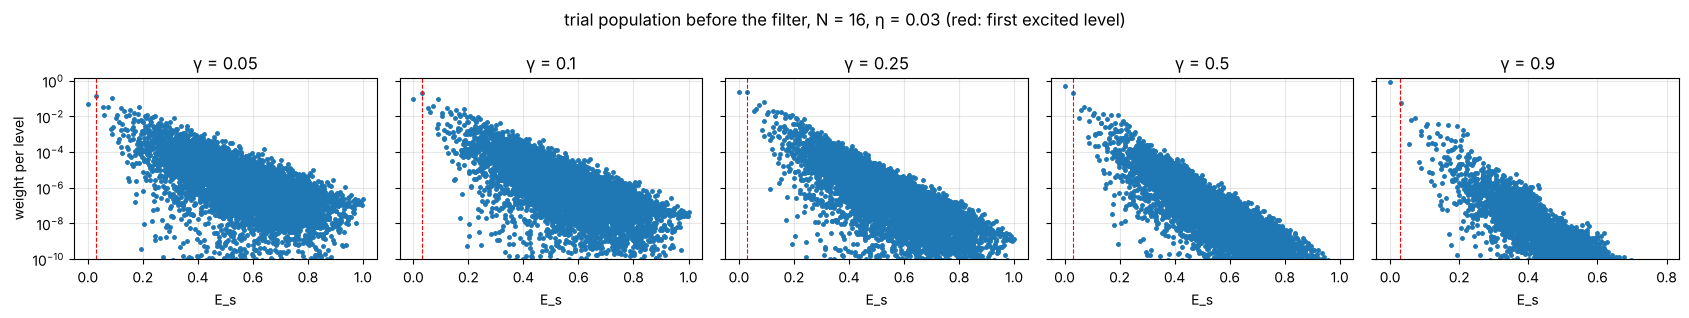

In [5]:
for col in ("w_first_excited", "w_excited_below_2eta", "levels_above_1e3", "eff_excited_levels", "mean_Es_excited"):
    print(col, "(rows N; columns η, γ)")
    display(pop.pivot_table(index="N", columns=["eta", "gamma"], values=col).round(4))

N0, e0 = max(NS), ETAS[1]
if (N0, e0) in spectra:
    Es, w, gams = spectra[N0, e0]
    fig, ax = plt.subplots(1, len(gams), figsize=(3.4 * len(gams), 3.2), sharey=True)
    for a, j in zip(np.atleast_1d(ax), range(len(gams))):
        o = np.argsort(Es); st = np.flatnonzero(np.r_[True, np.diff(Es[o]) > 1e-7])
        El, wl = Es[o][st], np.add.reduceat(w[o, j], st)
        a.semilogy(El[wl > 1e-12], wl[wl > 1e-12], "o", ms=2.5)
        a.axvline(e0, color="r", ls="--", lw=0.8)
        a.set(xlabel="E_s", title=f"γ = {gams[j]}", ylim=(1e-10, 1.5)); a.grid(alpha=0.3)
    np.atleast_1d(ax)[0].set_ylabel("weight per level")
    fig.suptitle(f"trial population before the filter, N = {N0}, η = {e0} (red: first excited level)"); fig.tight_layout(); plt.show()

## 5. Results

In [6]:
print(f"CNOT per success (filter only, 1 - F <= {EPS}); rows N, columns method, one table per (η, γ)")
for eta in ETAS:
    for g in GAMMAS:
        s = res[(res.eta == eta) & (res.gamma == g)]
        if len(s):
            print(f"\nη = {eta}, γ = {g}")
            t = s.pivot(index="N", columns="method", values="CNOT_per_success")[METHODS]
            t["AA rounds k"] = s[s.method == "QETU+AA"].set_index("N").AA_k
            t["qubits SBC+AA"] = s[s.method == "SBC+AA"].set_index("N").qubits
            display(t.style.format({m: "{:.4g}" for m in METHODS}))

# joint fits per method: ln C = c + α ln N + a ln(1/η) + b ln(1/γ)   (γ <= 0.5: away from the γ -> 1 corner)
fits = []
for name in METHODS:
    s = res[(res.method == name) & (res.gamma <= 0.5)]
    for col in ("CNOT_per_success", "Rz_per_success"):
        X = np.column_stack([np.ones(len(s)), np.log(s.N), -np.log(s.eta), -np.log(s.gamma)])
        coef, *_ = np.linalg.lstsq(X, np.log(s[col]), rcond=None)
        resid = np.log(s[col]) - X @ coef
        fits.append(dict(method=name, cost=col, C=np.exp(coef[0]), alpha_N=coef[1], a_eta=coef[2], b_gamma=coef[3],
                         R2=1 - resid @ resid / np.sum((np.log(s[col]) - np.log(s[col]).mean()) ** 2)))
fits = pd.DataFrame(fits)
print("\njoint fits  cost ≈ C · N^α · η^-a · γ^-b  (γ <= 0.5)")
display(fits.set_index(["method", "cost"]).round(3))

CNOT per success (filter only, 1 - F <= 0.01); rows N, columns method, one table per (η, γ)

η = 0.015, γ = 0.05


method,SBC,SBC+AA,QETU,QETU+AA,AA rounds k,qubits SBC+AA
N,,,,,,
6,7.979e+05,2.245e+05,8.129e+05,2.25e+05,4,18
8,5.481e+05,1.929e+05,5.55e+05,1.938e+05,3,14
10,4.875e+05,1.724e+05,4.944e+05,1.731e+05,3,16
12,7.619e+05,2.257e+05,7.791e+05,2.246e+05,3,24
14,7.91e+05,2.639e+05,8.059e+05,2.624e+05,3,26
16,8.744e+05,3.067e+05,8.885e+05,3.046e+05,3,28



η = 0.015, γ = 0.1


method,SBC,SBC+AA,QETU,QETU+AA,AA rounds k,qubits SBC+AA
N,,,,,,
6,1.888e+05,9.195e+04,1.923e+05,9.286e+04,2,12
8,2.75e+05,1.378e+05,2.785e+05,1.385e+05,2,14
10,2.454e+05,1.231e+05,2.489e+05,1.237e+05,2,16
12,3.029e+05,1.539e+05,3.063e+05,1.544e+05,2,18
14,3.988e+05,1.877e+05,4.063e+05,1.869e+05,2,26
16,4.403e+05,2.186e+05,4.474e+05,2.174e+05,2,28



η = 0.015, γ = 0.25


method,SBC,SBC+AA,QETU,QETU+AA,AA rounds k,qubits SBC+AA
N,,,,,,
6,7.616e+04,5.515e+04,7.759e+04,5.577e+04,1,12
8,7.71e+04,5.538e+04,7.855e+04,5.593e+04,1,14
10,9.866e+04,7.363e+04,1.001e+05,7.409e+04,1,16
12,1.217e+05,9.2e+04,1.231e+05,9.239e+04,1,18
14,1.451e+05,1.104e+05,1.465e+05,1.107e+05,1,20
16,8.575e+04,6.538e+04,8.713e+04,6.561e+04,1,22


... (32 outputs left out)


η = 0.1, γ = 0.9


method,SBC,SBC+AA,QETU,QETU+AA,AA rounds k,qubits SBC+AA
N,,,,,,
6,770,770,796.7,796.7,0,7
8,1133,1133,1159,1159,0,9
10,1501,1501,1527,1527,0,11
12,1870,1870,1896,1896,0,13
14,4515,4515,4569,4569,0,15
16,5260,5260,5314,5314,0,17



joint fits  cost ≈ C · N^α · η^-a · γ^-b  (γ <= 0.5)


C  alpha_N  a_eta  b_gamma     R2
method  cost                                                    
SBC     CNOT_per_success  25.832    0.916  1.043    1.193  0.966
        Rz_per_success    13.118    0.913  1.041    1.193  0.966
SBC+AA  CNOT_per_success  38.854    0.969  0.980    0.756  0.941
        Rz_per_success    22.476    0.963  0.938    0.787  0.937
QETU    CNOT_per_success  27.577    0.898  1.042    1.194  0.966
        Rz_per_success    14.839    0.882  1.036    1.194  0.967
QETU+AA CNOT_per_success  36.041    0.970  1.011    0.733  0.945
        Rz_per_success    19.527    0.966  0.994    0.743  0.944

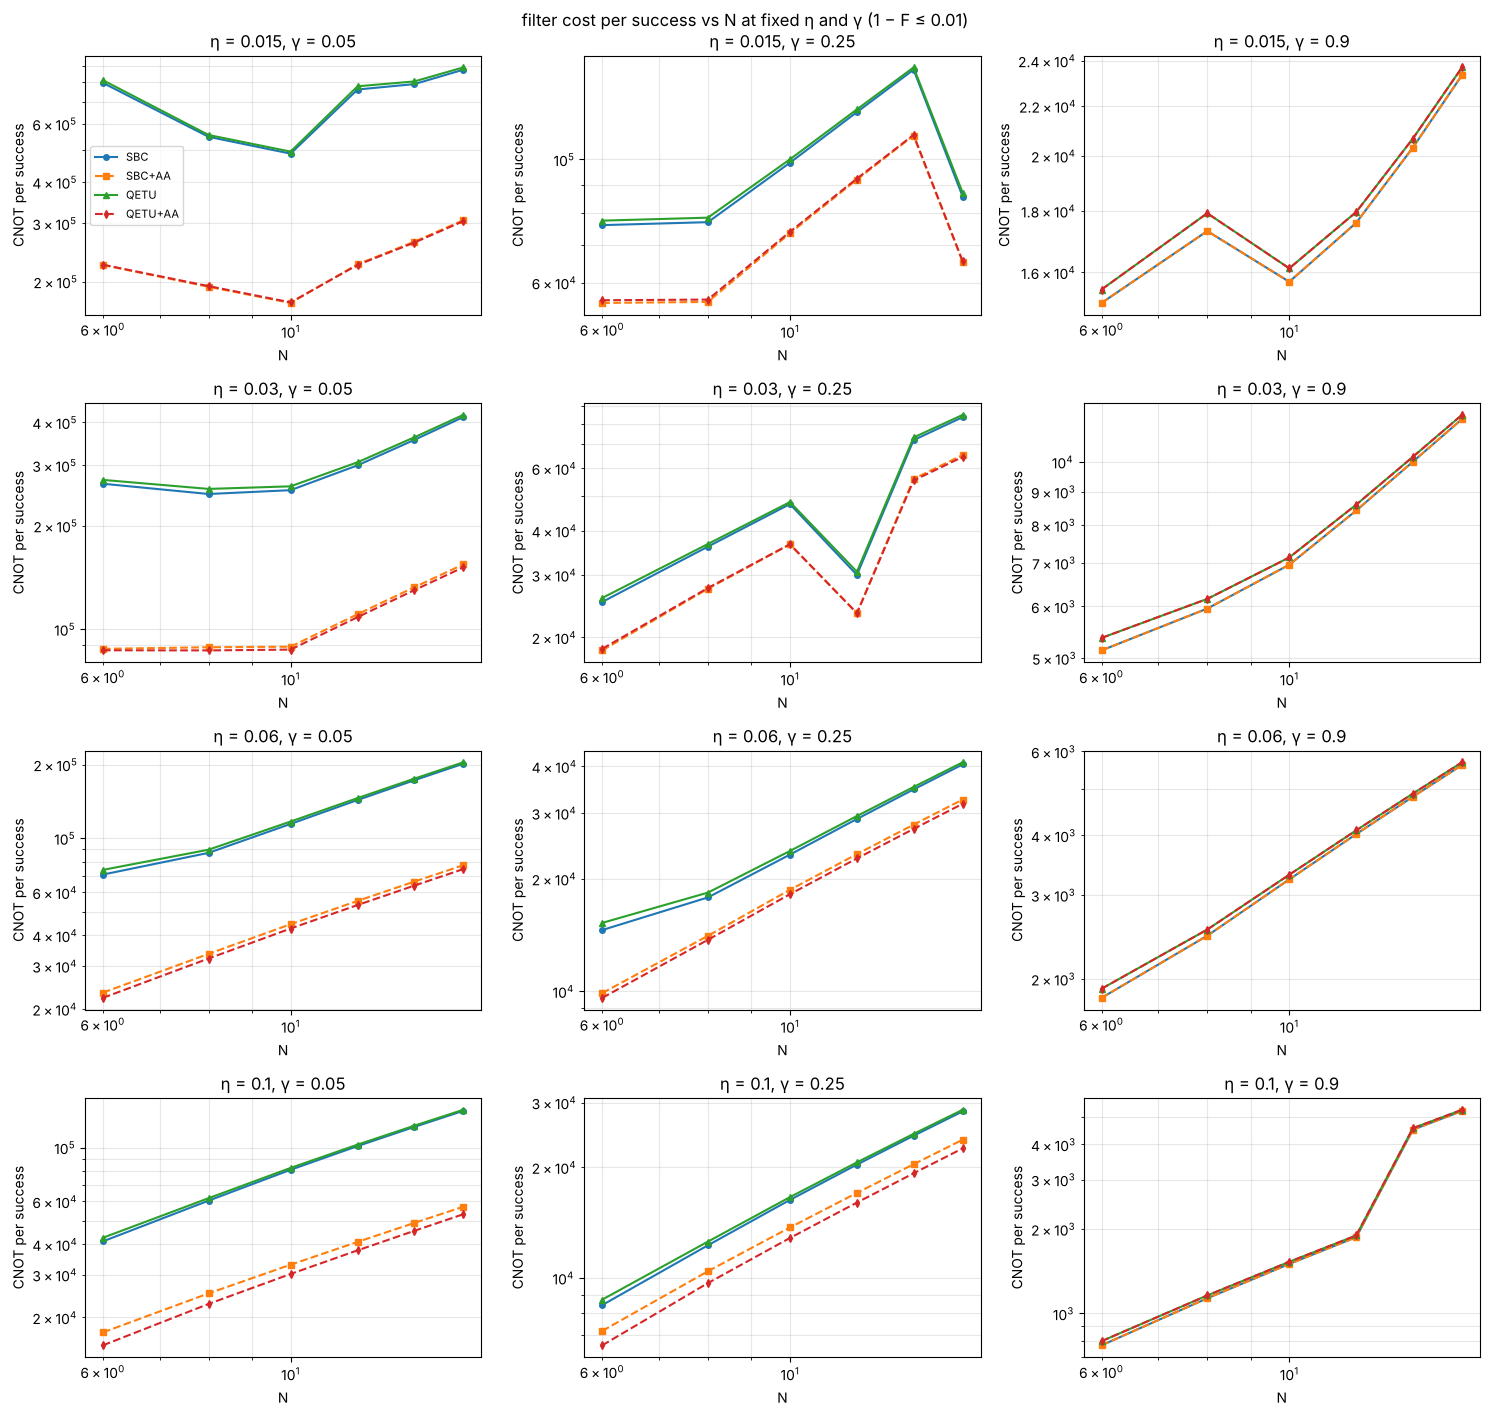

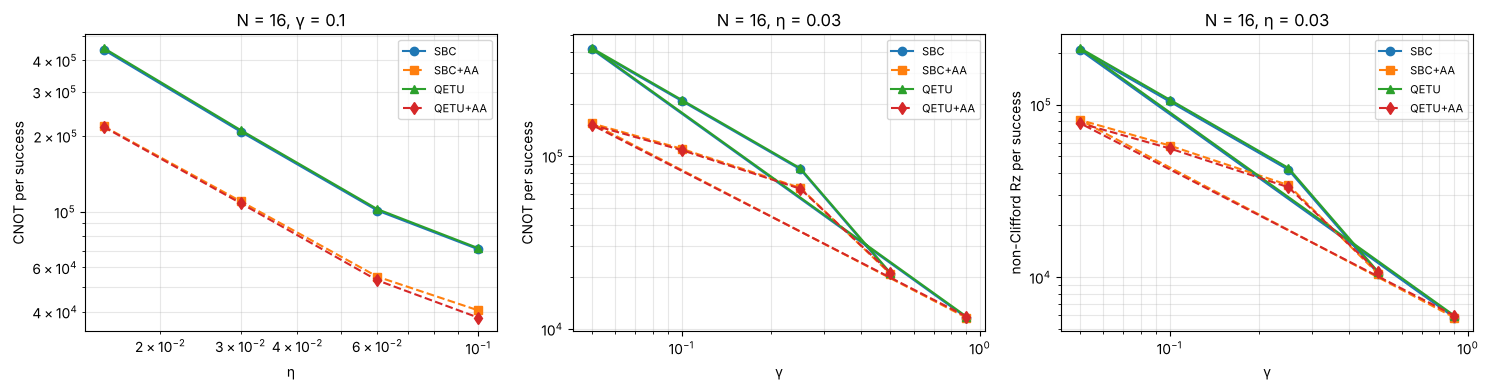

In [7]:
mk = dict(zip(METHODS, ["o-", "s--", "^-", "d--"]))
fig, ax = plt.subplots(len(ETAS), 3, figsize=(15, 3.6 * len(ETAS)), squeeze=False)
for i, eta in enumerate(ETAS):
    for j, g in enumerate([0.05, 0.25, 0.9]):
        s = res[(res.eta == eta) & (res.gamma == g)]
        for name in METHODS:
            t = s[s.method == name]
            ax[i, j].loglog(t.N, t.CNOT_per_success, mk[name], label=name, ms=4)
        ax[i, j].set(xlabel="N", ylabel="CNOT per success", title=f"η = {eta}, γ = {g}")
        ax[i, j].grid(alpha=0.3, which="both")
ax[0, 0].legend(fontsize=8)
fig.suptitle(f"filter cost per success vs N at fixed η and γ (1 − F ≤ {EPS})"); fig.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
N0 = max(NS)
for name in METHODS:
    s = res[(res.method == name) & (res.N == N0) & (res.gamma == 0.1)]
    ax[0].loglog(s.eta, s.CNOT_per_success, mk[name], label=name)
    s = res[(res.method == name) & (res.N == N0) & (res.eta == ETAS[1])]
    ax[1].loglog(s.gamma, s.CNOT_per_success, mk[name], label=name)
    s = res[(res.method == name) & (res.N == N0) & (res.eta == ETAS[1])]
    ax[2].loglog(s.gamma, s.Rz_per_success, mk[name], label=name)
ax[0].set(xlabel="η", ylabel="CNOT per success", title=f"N = {N0}, γ = 0.1")
ax[1].set(xlabel="γ", ylabel="CNOT per success", title=f"N = {N0}, η = {ETAS[1]}")
ax[2].set(xlabel="γ", ylabel="non-Clifford Rz per success", title=f"N = {N0}, η = {ETAS[1]}")
for a in ax:
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=8)
fig.tight_layout(); plt.show()